# 06 · General linear model framework

How correlation, ANOVA, regression and ANCOVA are one model, applied to two coverage proxies. Also builds the shared modelling table `analysis_outputs/model_frame.parquet` used by notebooks 07-13.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "analysis_outputs").exists())
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})

REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))

# one table: Overture aggregates + ACS + strata, one row per scored tract (built by the earlier notebooks)
df = pd.read_parquet(OUT / "tract_analysis_table.parquet")
df["land_km2"] = df.ALAND / 1e6

def box_by_region(ax, col, data=None, log=False, title="", ylabel=None):
    """Box plot of one column for each region (log10 if log=True), n shown under each box."""
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    """Number of values outside the 1.5 x IQR fences."""
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    """Annotated heatmap of a DataFrame."""
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

**One idea:** correlation, t-test, ANOVA, regression and ANCOVA are the same model, `y = X b + e`, with different design matrices.

The competition target is hidden, so this notebook works with two *observable proxies*:

| proxy | meaning |
|---|---|
| `y_poi` | log of POIs per 100 buildings (how well-mapped are places) |
| `proxy_bldg_gap` | `1 - min(1, Overture buildings / USFS building count)`. Same clipped-at-0 shape as the real building component. USFS provenance is an open rules question, so exploration only. |

Section 0 also **saves `analysis_outputs/model_frame.parquet`**, which notebooks 07-13 read.

## 0. Build the modelling frame (one row per scored tract)

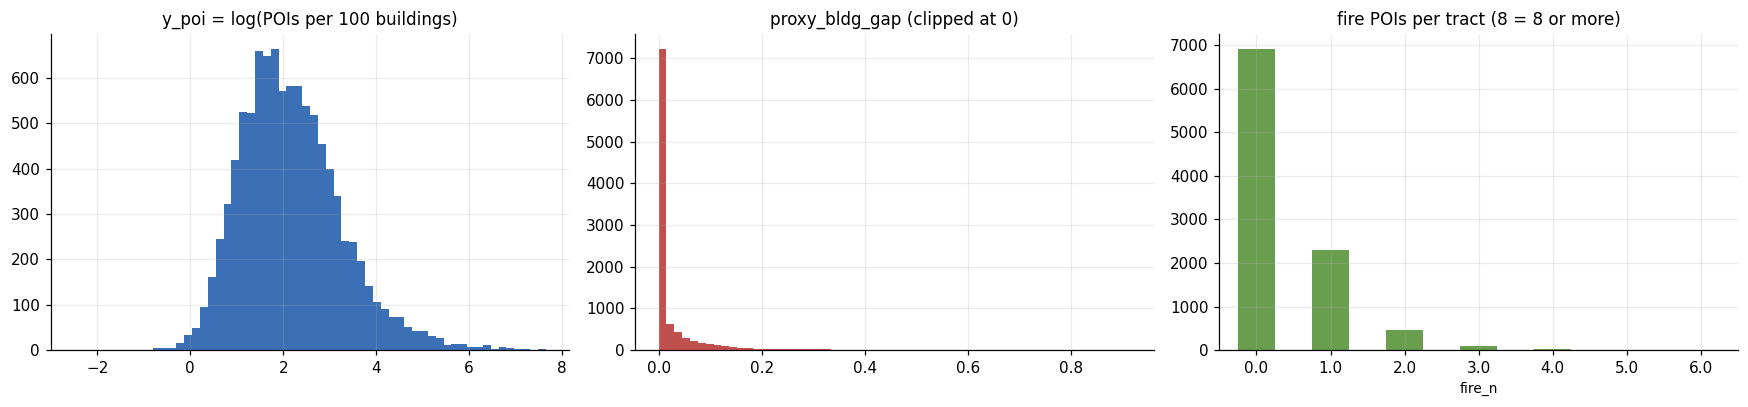

(9794, 31) | tracts with proxy_bldg_gap == 0: 0.641 | NaN gap: 2
                 count   mean    std    min    25%    50%    75%    max
y_poi           9792.0  2.172  1.092 -2.495  1.404  2.059  2.808  7.646
proxy_bldg_gap  9792.0  0.024  0.061  0.000  0.000  0.000  0.018  0.913
fire_n          9794.0  0.372  0.659  0.000  0.000  0.000  1.000  6.000


In [2]:
import statsmodels.api as sm, statsmodels.formula.api as smf
SEED = 42
d = df; f = pd.DataFrame({"GEOID": d.GEOID, "region": d.region})
f["pop_density"] = d.pop_total / d.land_km2.replace(0, np.nan); f["log_pop_density"] = np.log1p(f.pop_density); f["log_area_km2"] = np.log(d.land_km2.clip(lower=0.01))
for new, old in [("pct_urban", "pct_urban"), ("svi", "svi_overall"), ("cvi", "cvi_overall"), ("ruca", "ruca_primary"), ("water_share", "water_share"), ("share_msft", "share_msft"), ("share_osm", "share_osm"),
                 ("hwy_share", "hwy_share_of_road_km"), ("wildfire_whp", "usfs_WHP_mean"), ("drought_summer", "usdm_summer_dsci"), ("heat_wbgt28", "gehe_wbgt28_days_mean"), ("heat_days_summer", "epht_heat_days_summer"),
                 ("bldg_n", "bldg_n"), ("poi_n", "poi_n"), ("pop_total", "pop_total"), ("fire_n", "poi_n_fire"), ("ems_n", "poi_n_ems"), ("school_n", "poi_n_school")]: f[new] = d[old]
f["rural"] = d.rural.astype(int); f["tribal"] = d.tribal.astype(int); f["bldg_per_hu"] = d.bldg_per_hu.replace(np.inf, np.nan); f["log_road_density"] = np.log1p(d.road_km_per_km2)
f["transit_any"] = (d.infra_n_transit > 0).astype(int); f["no_fire"] = (d.poi_n_fire == 0).astype(int)
f["y_poi"] = np.log(d.poi_per_100_bldg.replace([0, np.inf], np.nan))
f["proxy_bldg_gap"] = 1 - (d.bldg_n / d.usfs_BuildingCount_sum.replace(0, np.nan)).clip(upper=1)
f.to_parquet(OUT / "model_frame.parquet")
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(f.y_poi.dropna(), bins=60, color="#3b6fb6"); ax[0].set_title("y_poi = log(POIs per 100 buildings)")
ax[1].hist(f.proxy_bldg_gap.dropna(), bins=60, color="#c0504d"); ax[1].set_title("proxy_bldg_gap (clipped at 0)")
f.fire_n.clip(upper=8).value_counts().sort_index().plot.bar(ax=ax[2], color="#6a9e4f", rot=0); ax[2].set_title("fire POIs per tract (8 = 8 or more)")
plt.tight_layout(); plt.show()
print(f.shape, "| tracts with proxy_bldg_gap == 0:", round((f.proxy_bldg_gap == 0).mean(), 3), "| NaN gap:", int(f.proxy_bldg_gap.isna().sum()))
print(f[["y_poi", "proxy_bldg_gap", "fire_n"]].describe().T.round(3).to_string())

**Takeaway:** `y_poi` is roughly bell-shaped, so ordinary least squares is a fair start. `proxy_bldg_gap` has a large spike at exactly 0 (like the real target), and fire POIs are small counts. Both motivate the GLMs in notebook 08.

## 1. Correlation is a simple regression
For standardised variables the slope equals Pearson's r, with the same p-value.

Pearson r = 0.3424 (p = 1.88e-267) | standardised slope = 0.3424 (p = 1.88e-267)


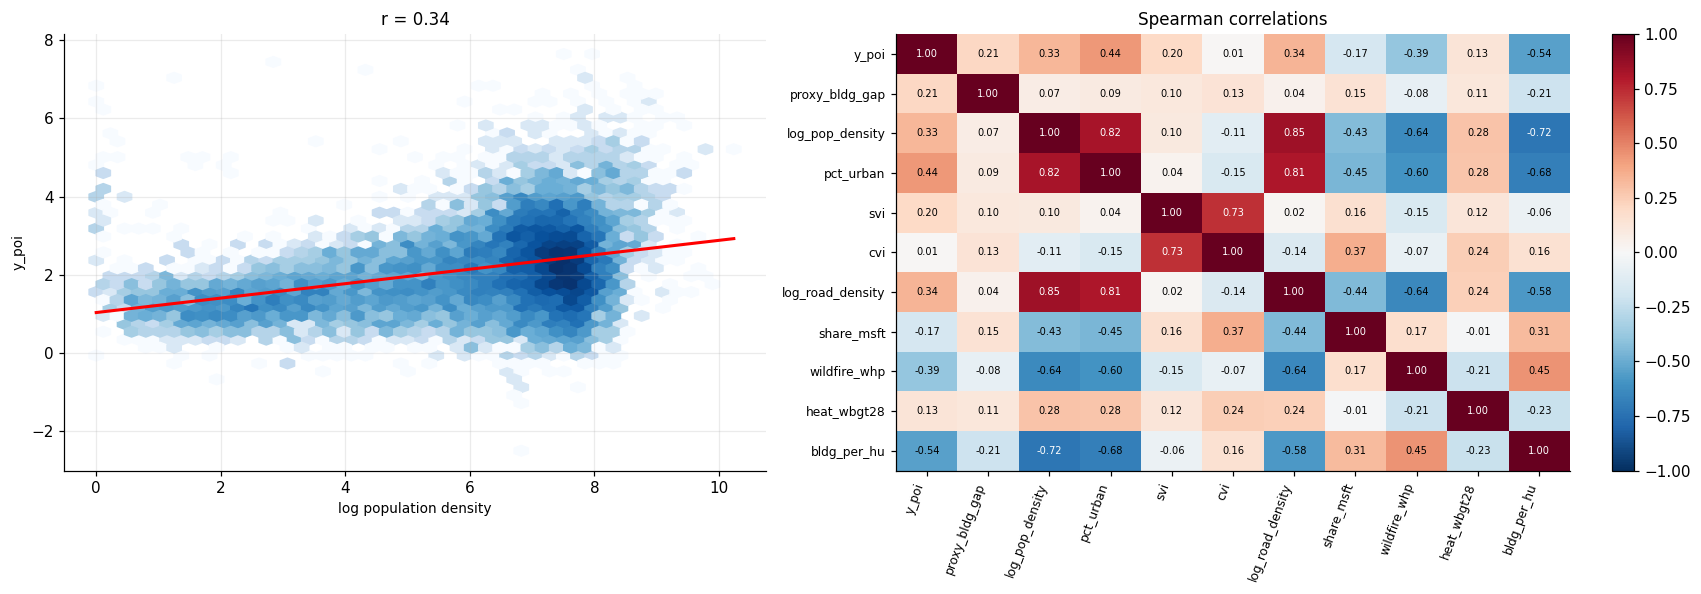

In [3]:
s = f[["y_poi", "log_pop_density"]].dropna(); r, p_r = stats.pearsonr(s.log_pop_density, s.y_poi); z = (s - s.mean()) / s.std(); fit = smf.ols("y_poi ~ log_pop_density", z).fit()
print(f"Pearson r = {r:.4f} (p = {p_r:.2e}) | standardised slope = {fit.params['log_pop_density']:.4f} (p = {fit.pvalues['log_pop_density']:.2e})")
num = f[["y_poi", "proxy_bldg_gap", "log_pop_density", "pct_urban", "svi", "cvi", "log_road_density", "share_msft", "wildfire_whp", "heat_wbgt28", "bldg_per_hu"]].corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.2]})
ax[0].hexbin(s.log_pop_density, s.y_poi, gridsize=45, cmap="Blues", mincnt=1, bins="log"); xs = np.linspace(s.log_pop_density.min(), s.log_pop_density.max(), 50)
ax[0].plot(xs, np.polyval(np.polyfit(s.log_pop_density, s.y_poi, 1), xs), "r", lw=2); ax[0].set(xlabel="log population density", ylabel="y_poi", title=f"r = {r:.2f}")
plt.colorbar(heat(ax[1], num, fs=6.5, rot=70), ax=ax[1]); ax[1].set_title("Spearman correlations")
plt.tight_layout(); plt.show()

**Takeaway:** r and the standardised slope agree to every digit (+0.3424), so correlation *is* regression. Denser tracts have more POIs per building: rural tracts have many outbuildings but few places, so this proxy partly measures urbanity.

## 2. ANOVA is regression on dummy variables
One-way ANOVA across regions gives the same F as the overall test of `y ~ C(region)`.

f_oneway: F = 56.08, p = 7.70e-47 | OLS overall F = 56.08, p = 7.70e-47 | R2 = 0.022
              sum_sq      df       F  PR(>F)
C(region)    261.604     4.0  56.076     0.0
Residual   11414.504  9787.0     NaN     NaN


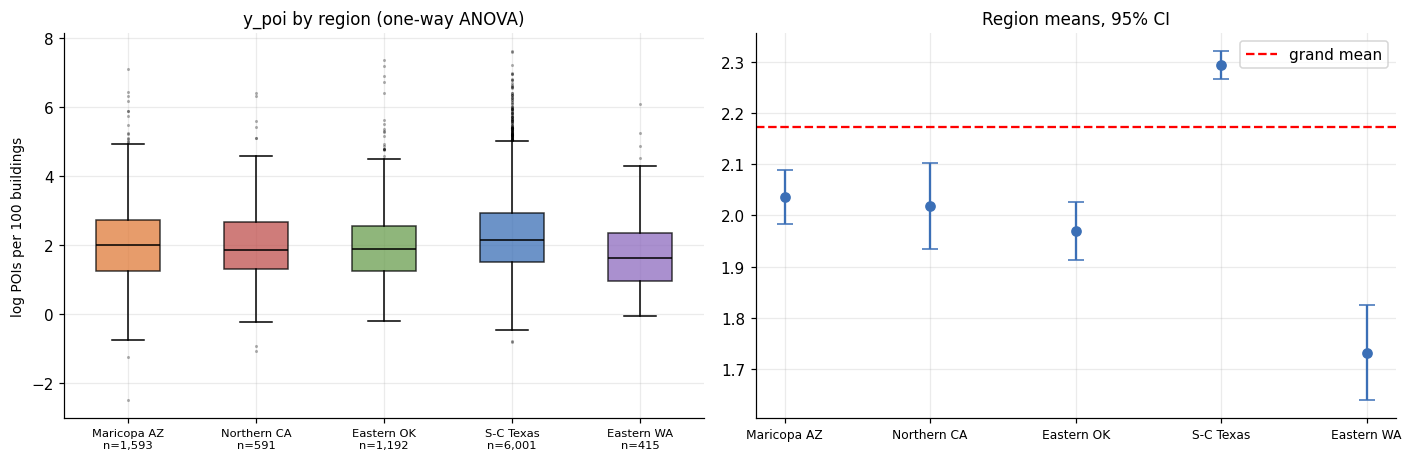

In [4]:
groups = [g.y_poi.dropna().values for _, g in f.groupby("region")]; F, p = stats.f_oneway(*groups); m = smf.ols("y_poi ~ C(region)", f).fit()
print(f"f_oneway: F = {F:.2f}, p = {p:.2e} | OLS overall F = {m.fvalue:.2f}, p = {m.f_pvalue:.2e} | R2 = {m.rsquared:.3f}"); print(sm.stats.anova_lm(m, typ=2).round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3)); box_by_region(ax[0], "y_poi", data=f, title="y_poi by region (one-way ANOVA)", ylabel="log POIs per 100 buildings")
mu = f.groupby("region").y_poi.agg(["mean", "sem"]).reindex(REG); ax[1].errorbar(range(5), mu["mean"], yerr=1.96 * mu["sem"], fmt="o", capsize=5, color="#3b6fb6"); ax[1].axhline(f.y_poi.mean(), color="r", ls="--", label="grand mean")
ax[1].set_xticks(range(5)); ax[1].set_xticklabels([NAME[r] for r in REG], fontsize=8); ax[1].set_title("Region means, 95% CI"); ax[1].legend()
plt.tight_layout(); plt.show()

**Takeaway:** the two routes give the same F (56.08). Region explains only about 2% of the variance (R2 = 0.022): significant, but most variation is *within* regions.

## 3. Multiple regression
Standardised predictors so coefficients are comparable; robust (HC3) errors because residual tails are heavy.

n = 9706 | R2 = 0.207 | adj R2 = 0.206
                   coef      p
cvi              -0.164  0.000
rural            -0.147  0.000
share_msft       -0.063  0.000
heat_wbgt28      -0.023  0.081
log_pop_density  -0.021  0.581
wildfire_whp      0.012  0.059
tribal            0.033  0.016
log_road_density  0.264  0.000
svi               0.298  0.000


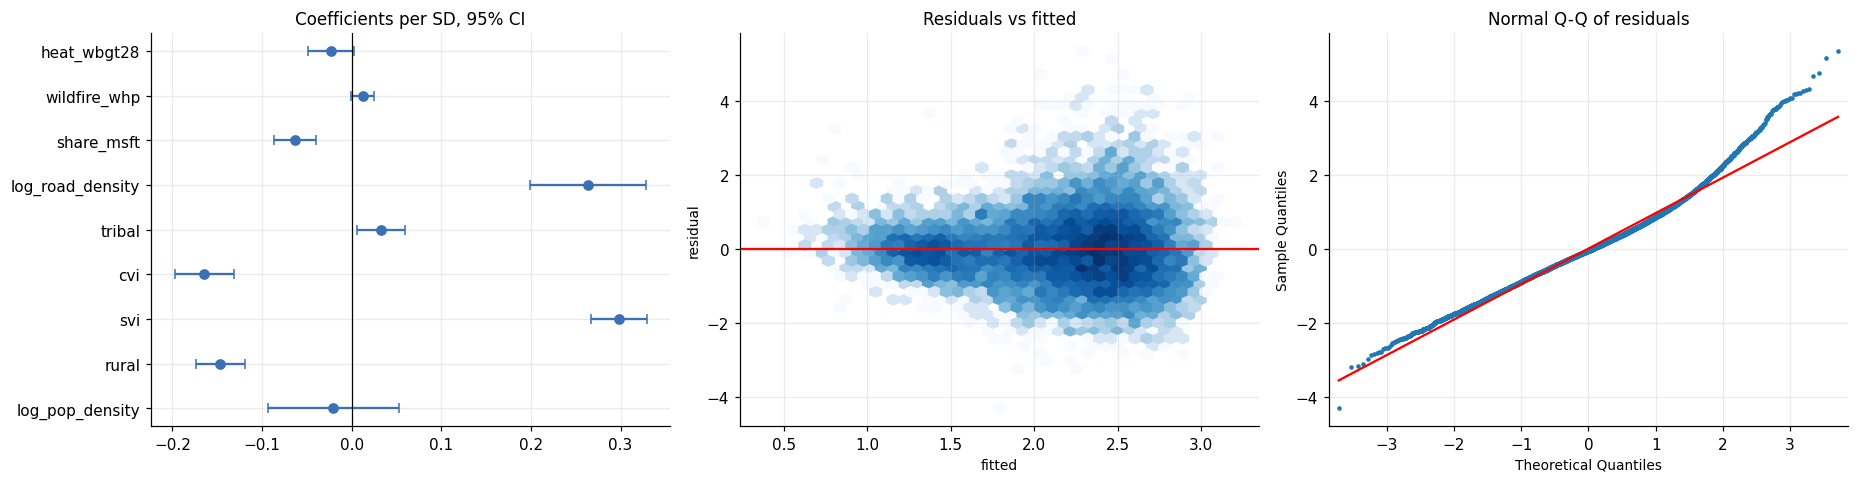

In [5]:
cols = ["log_pop_density", "rural", "svi", "cvi", "tribal", "log_road_density", "share_msft", "wildfire_whp", "heat_wbgt28"]
s = f[["y_poi", "region"] + cols].dropna().copy(); s[cols] = (s[cols] - s[cols].mean()) / s[cols].std()
m = smf.ols("y_poi ~ " + " + ".join(cols) + " + C(region)", s).fit(cov_type="HC3"); ci = m.conf_int().loc[cols]; co = m.params[cols]
print(f"n = {int(m.nobs)} | R2 = {m.rsquared:.3f} | adj R2 = {m.rsquared_adj:.3f}"); print(pd.DataFrame({"coef": co, "p": m.pvalues[cols]}).sort_values("coef").round(3).to_string())
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].errorbar(co, range(len(cols)), xerr=[co - ci[0], ci[1] - co], fmt="o", capsize=3, color="#3b6fb6"); ax[0].axvline(0, color="k", lw=.8); ax[0].set_yticks(range(len(cols))); ax[0].set_yticklabels(cols); ax[0].set_title("Coefficients per SD, 95% CI")
ax[1].hexbin(m.fittedvalues, m.resid, gridsize=40, cmap="Blues", mincnt=1, bins="log"); ax[1].axhline(0, color="r"); ax[1].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
sm.qqplot(m.resid, line="s", ax=ax[2], markersize=2); ax[2].set_title("Normal Q-Q of residuals")
plt.tight_layout(); plt.show()

**Takeaway:** the covariates plus region explain about 21% of the variance (R2 = 0.207). Use the coefficient plot for sign and size; the Q-Q plot shows heavier-than-normal tails, which is why the errors are robust.

## 4. ANCOVA: compare groups after adjusting for a covariate
Do tribal tracts have fewer POIs per building *after* accounting for how dense they are?

unadjusted tribal effect: -0.397 (p = 8.1e-25)
ANCOVA-adjusted effect  : -0.066 (p = 0.077)
interaction p = 0.002


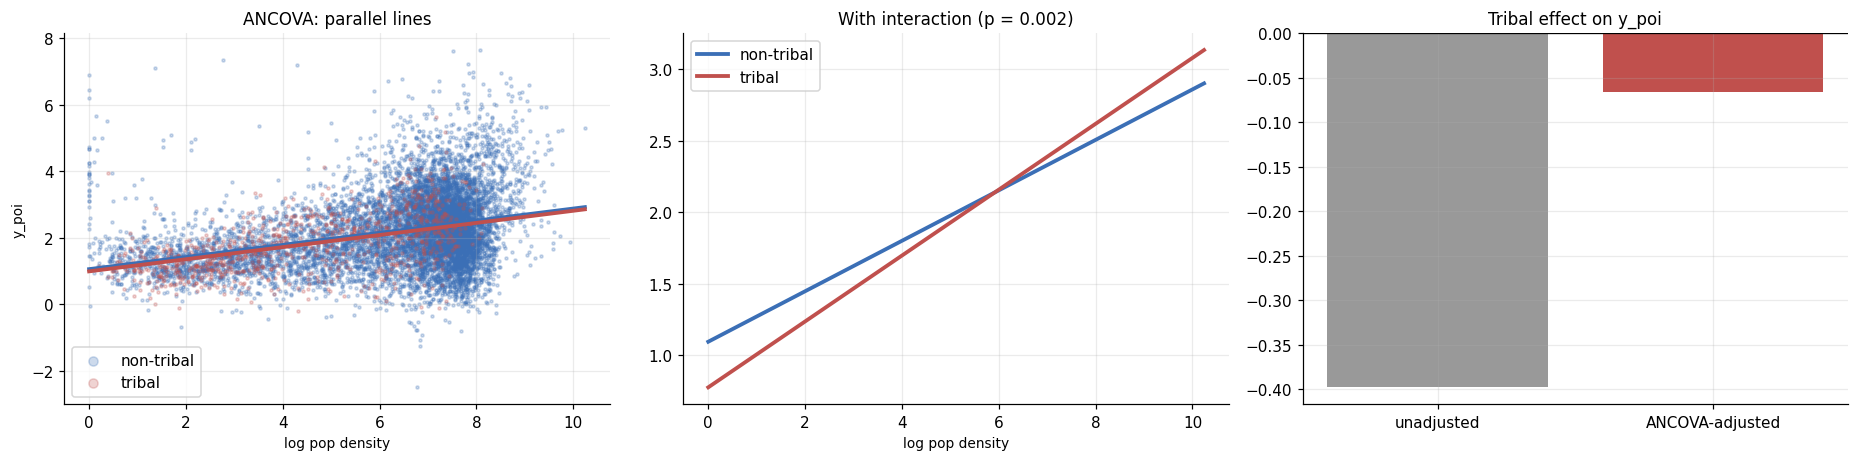

In [6]:
s = f[["y_poi", "tribal", "log_pop_density", "region"]].dropna()
raw = smf.ols("y_poi ~ tribal", s).fit(); anc = smf.ols("y_poi ~ tribal + log_pop_density", s).fit(); inter = smf.ols("y_poi ~ tribal * log_pop_density", s).fit()
print(f"unadjusted tribal effect: {raw.params['tribal']:+.3f} (p = {raw.pvalues['tribal']:.1e})\nANCOVA-adjusted effect  : {anc.params['tribal']:+.3f} (p = {anc.pvalues['tribal']:.3f})\ninteraction p = {inter.pvalues['tribal:log_pop_density']:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3)); xs = np.linspace(s.log_pop_density.min(), s.log_pop_density.max(), 20)
for t, c in ((0, "#3b6fb6"), (1, "#c0504d")):
    g = s[s.tribal == t]; ax[0].scatter(g.log_pop_density, g.y_poi, s=4, alpha=.25, color=c, label=["non-tribal", "tribal"][t]); ax[0].plot(xs, anc.params["Intercept"] + anc.params["tribal"] * t + anc.params["log_pop_density"] * xs, color=c, lw=2.5)
    ax[1].plot(xs, inter.params["Intercept"] + inter.params["tribal"] * t + (inter.params["log_pop_density"] + inter.params["tribal:log_pop_density"] * t) * xs, color=c, lw=2.5, label=["non-tribal", "tribal"][t])
ax[0].set(xlabel="log pop density", ylabel="y_poi", title="ANCOVA: parallel lines"); ax[0].legend(markerscale=3); ax[1].set(xlabel="log pop density", title=f"With interaction (p = {inter.pvalues['tribal:log_pop_density']:.3f})"); ax[1].legend()
ax[2].bar(["unadjusted", "ANCOVA-adjusted"], [raw.params["tribal"], anc.params["tribal"]], color=["#999", "#c0504d"]); ax[2].axhline(0, color="k"); ax[2].set_title("Tribal effect on y_poi")
plt.tight_layout(); plt.show()

**Takeaway:** the raw gap of -0.40 shrinks to -0.07 (p = 0.077, not significant) once density is held fixed. The covariate absorbed most of what looked like a group effect, a first hint of confounding (notebooks 11-13). The slopes do differ by group (interaction p = 0.002), so a single adjusted number is only a summary.

## 5. Case study: ridge regression for the clipped building gap
Predict `proxy_bldg_gap` from tract features. 5-fold CV RMSE (the competition metric) against two baselines.

RMSE constant mean : 0.0606
RMSE region means  : 0.0603
RMSE ridge         : 0.0585


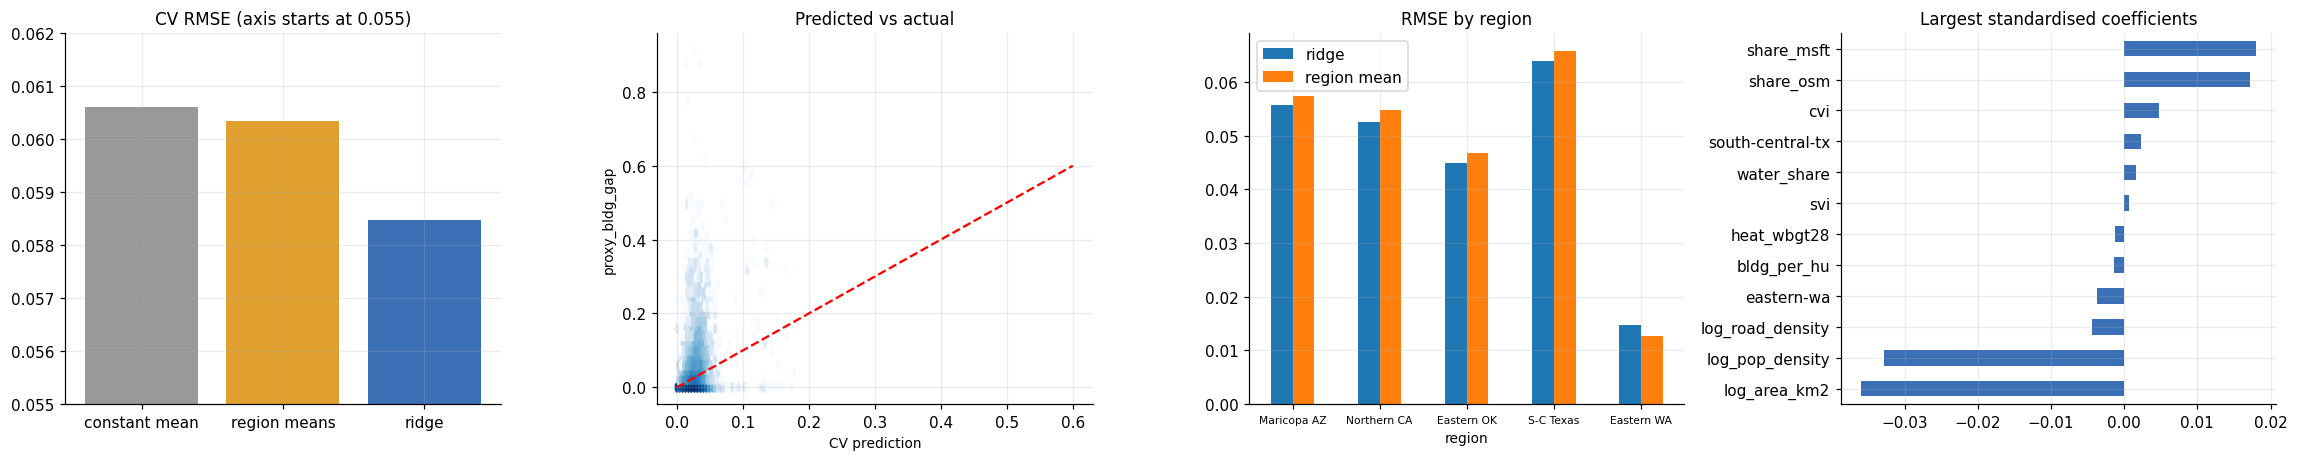

In [7]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
feat = ["log_pop_density", "rural", "svi", "cvi", "tribal", "log_road_density", "share_msft", "share_osm", "wildfire_whp", "heat_wbgt28", "bldg_per_hu", "log_area_km2", "water_share"]
s = f.dropna(subset=["proxy_bldg_gap"]).reset_index(drop=True); X = pd.concat([s[feat], pd.get_dummies(s.region, dtype=float)], axis=1); y = s.proxy_bldg_gap
cv = KFold(5, shuffle=True, random_state=SEED); base = cross_val_predict(LinearRegression(), pd.get_dummies(s.region, dtype=float), y, cv=cv)
mdl = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))); pred = np.clip(cross_val_predict(mdl, X, y, cv=cv), 0, 1)
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2))); R = {"constant mean": rmse(y.mean(), y), "region means": rmse(base, y), "ridge": rmse(pred, y)}
print("\n".join(f"RMSE {k:14s}: {v:.4f}" for k, v in R.items()))
per = pd.DataFrame({"ridge": (pred - y) ** 2, "region mean": (base - y) ** 2}).groupby(s.region).mean().pow(.5).reindex(REG); mdl.fit(X, y); co = pd.Series(mdl[-1].coef_, X.columns).sort_values()
fig, ax = plt.subplots(1, 4, figsize=(21, 4.3))
ax[0].bar(list(R), list(R.values()), color=["#999", "#e0a030", "#3b6fb6"]); ax[0].set_ylim(.055, .062); ax[0].set_title("CV RMSE (axis starts at 0.055)")
ax[1].hexbin(pred, y, gridsize=40, cmap="Blues", mincnt=1, bins="log"); ax[1].plot([0, .6], [0, .6], "r--"); ax[1].set(xlabel="CV prediction", ylabel="proxy_bldg_gap", title="Predicted vs actual")
per.plot.bar(ax=ax[2], rot=0); ax[2].set_xticklabels([NAME[r] for r in REG], fontsize=7); ax[2].set_title("RMSE by region")
co.iloc[np.r_[0:6, -6:0]].plot.barh(ax=ax[3], color="#3b6fb6"); ax[3].set_title("Largest standardised coefficients")
plt.tight_layout(); plt.show()

**Takeaway:** RMSE only falls from 0.0606 (constant) to 0.0603 (region means) to 0.0585 (ridge), so tract features explain little of this zero-heavy outcome. Gains must come from modelling the zero spike and the region effect (notebooks 08 and 13).